In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from lingua import Language, LanguageDetectorBuilder
from utils import load_data, process_data

In [5]:
df = load_data() #load already removes duplicate rows


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
Index: 63678 entries, 0 to 72132
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   title      63160 non-null  str  
 1   text       63639 non-null  str  
 2   labels     63678 non-null  int64
 3   full_text  63678 non-null  str  
dtypes: int64(1), str(3)
memory usage: 2.4 MB


In [8]:
df.isna().sum()

title        518
text          39
labels         0
full_text      0
dtype: int64

labels have no nulls, check if there are any columns where both title and text are nulls

In [9]:
mask = df["title"].isna() & df["text"].isna()
mask.sum()

np.int64(0)

will have to concatenate the rows with the nulls in mind

In [10]:
df.describe(include='all')

,title,text,labels,full_text
count,63160,63639,63678.000000,63678
unique,62347,62718,NaN,63676
top,Factbox: Trump fills top jobs for his administ...,,NaN,Pence says NAFTA renegotiation will be a 'win ...
freq,14,525,NaN,2
mean,NaN,NaN,0.453642,NaN
std,NaN,NaN,0.497850,NaN
min,NaN,NaN,0.000000,NaN
25%,NaN,NaN,0.000000,NaN
50%,NaN,NaN,0.000000,NaN
75%,NaN,NaN,1.000000,NaN


In [11]:
raw_counts = df["labels"].value_counts()

percentages = 100*round(df["labels"].value_counts(normalize=True), 3)

percentage_repr = percentages.astype(str) + "%"

real_fake_stats = pd.concat([raw_counts.rename("count"), percentage_repr.rename("percentages"), ], axis=1)

real_fake_stats.index = real_fake_stats.index.map({0 : "True", 1: "Fake"})

real_fake_stats.index.name = None

real_fake_stats

,count,percentages
True,34791,54.6%
Fake,28887,45.4%


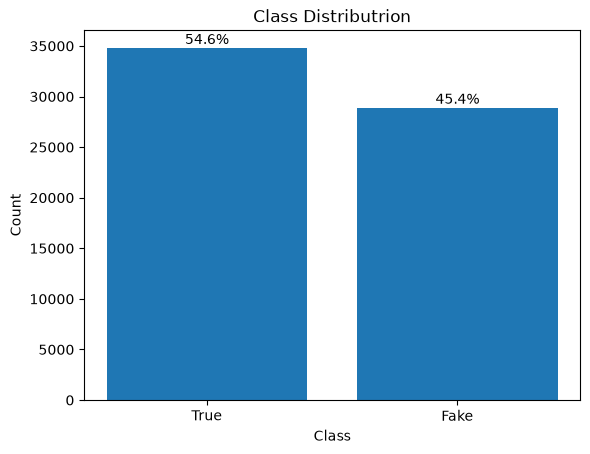

In [12]:
fig, ax = plt.subplots()

bars = ax.bar(real_fake_stats.index , real_fake_stats["count"])

ax.set_title("Class Distributrion")

ax.set_xlabel("Class")

ax.set_ylabel("Count")

ax.bar_label(bars, labels=real_fake_stats["percentages"], padding=0.5)

plt.show()

The two classes are ~51.4% and ~48.6%, this is relatively balanced, therefore accuracy metrics wont be misleading later on.

In [13]:
df["article_length"] = df["text"].str.split().str.len()
df["title_length"] = df["title"].str.split().str.len()
df["class"] = df["labels"].map({1: "Fake", 0: "True"}) #class label for visualizations

In [14]:
import seaborn as sns

<Axes: xlabel='class', ylabel='title_length'>

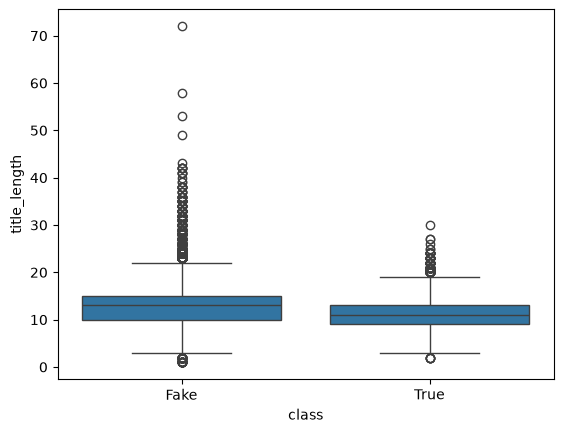

In [15]:


sns.boxplot(data= df, x= "class", y=  "title_length")

<Axes: xlabel='class', ylabel='article_length'>

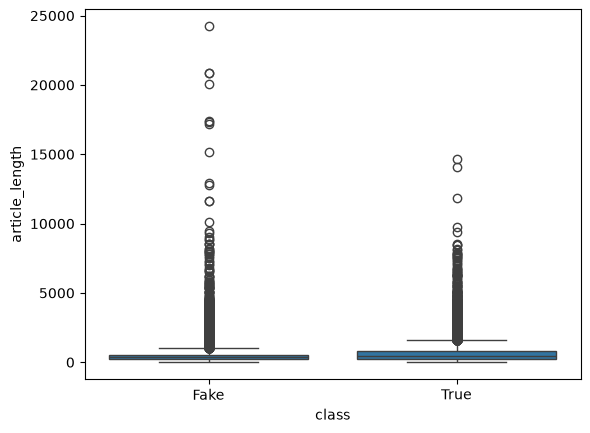

In [16]:
sns.boxplot(data= df, x= "class", y=  "article_length")

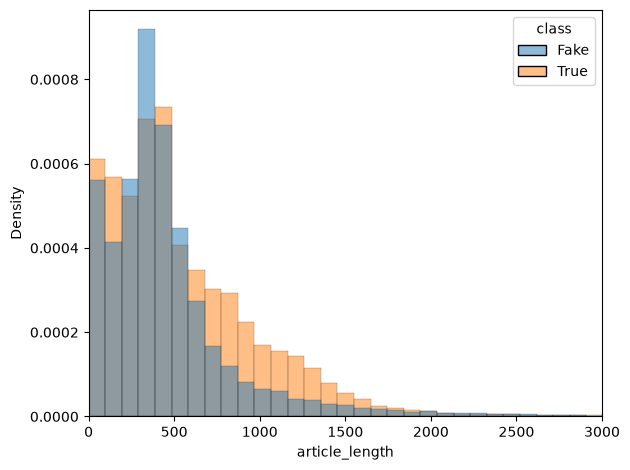

In [17]:
ax = sns.histplot(data = df,
            x = "article_length",
            hue = "class",
            bins = 250,
            kde = False,
            common_norm= True,
            stat = "density")
ax.set_xlim(0,3000)
plt.tight_layout()

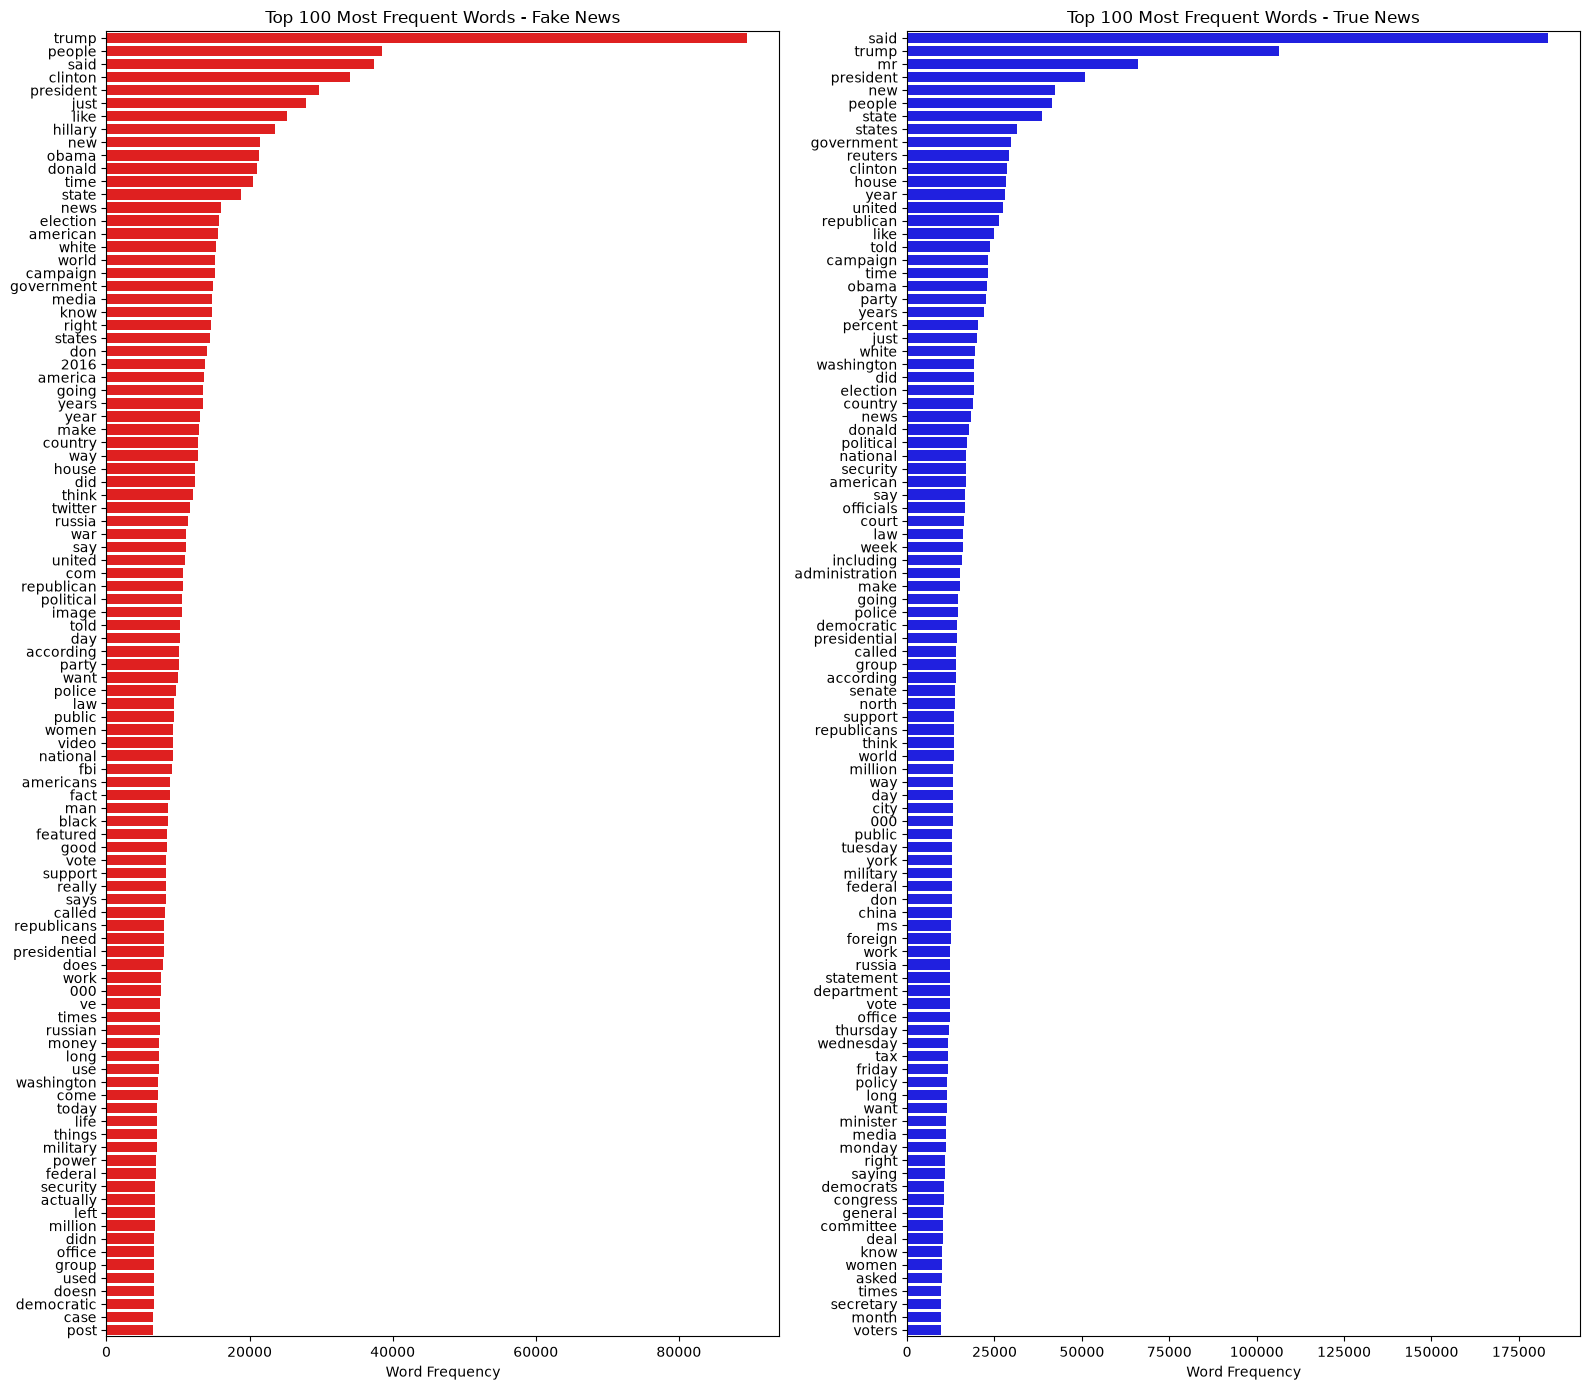

In [18]:

from sklearn.feature_extraction.text import CountVectorizer

fig, axes = plt.subplots(1, 2, figsize=(16, 14))

for ax, label, color in zip(
    axes,
    ["Fake", "True"],
    ["red", "blue"]
):
    texts = df.loc[df["class"] == label, "text"].fillna("")

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=100,
        min_df=2
    )

    X = vectorizer.fit_transform(texts)

    word_counts = X.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    sns.barplot(
        x=word_counts,
        y=words,
        ax=ax,
        color=color,
        order=words[word_counts.argsort()[::-1]]
    )

    ax.set_title(f"Top 100 Most Frequent Words - {label} News")
    ax.set_xlabel("Word Frequency")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

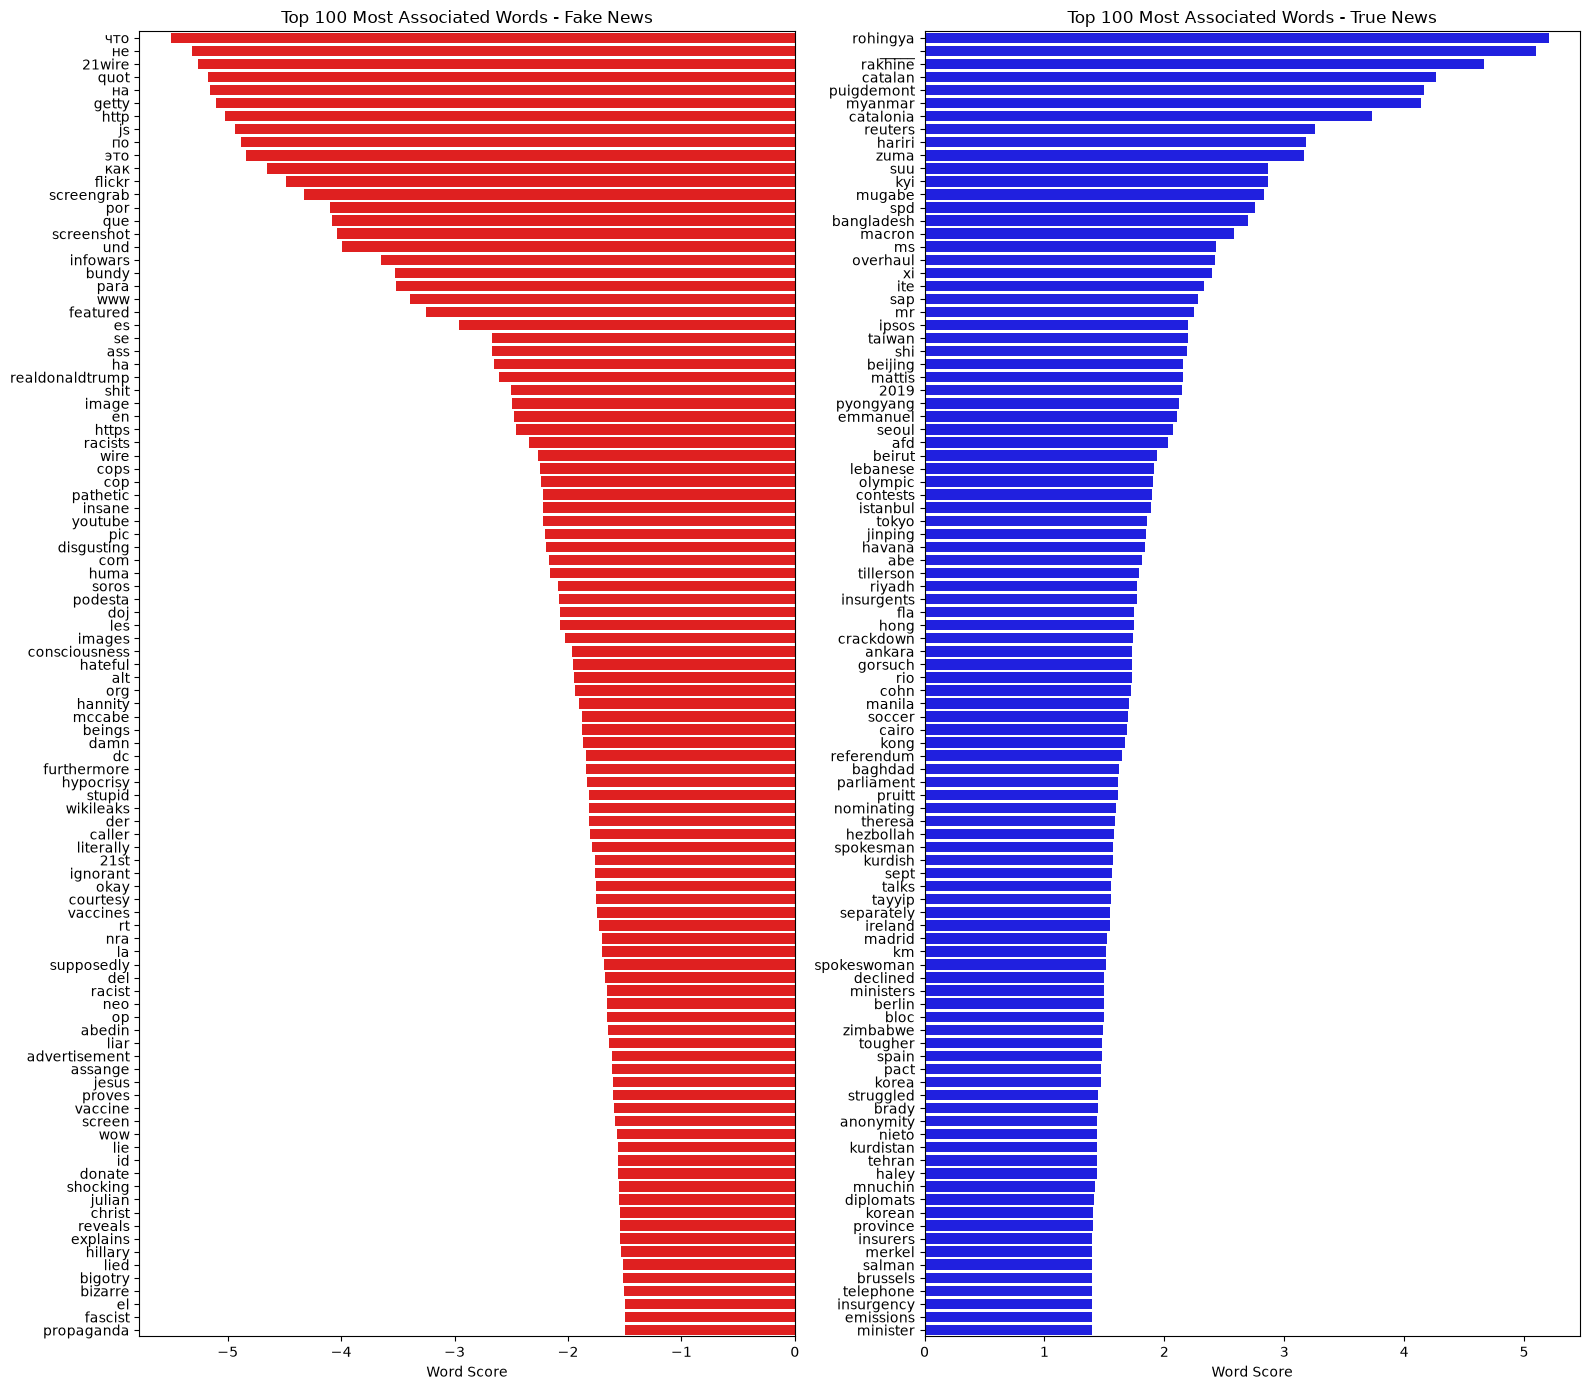

In [19]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2
)

X = vectorizer.fit_transform(df["text"].fillna(""))

words = vectorizer.get_feature_names_out()

fake_counts = np.asarray(
    X[(df["class"] == "Fake").to_numpy()].sum(axis=0)
).ravel()

true_counts = np.asarray(
    X[(df["class"] == "True").to_numpy()].sum(axis=0)
).ravel()

fake_freq = fake_counts / fake_counts.sum()

true_freq = true_counts / true_counts.sum()
alpha =  1e-6
log_scores = np.log((true_freq + alpha)/ (fake_freq + alpha))


fig, axes = plt.subplots(1, 2, figsize=(16, 14))

for ax, label, color in zip(
    axes,
    ["Fake", "True"],
    ["red", "blue"]
):
    class_words = pd.DataFrame({
    "words" : words,
    "log_scores" : log_scores
    }
    )
    ascending = True if label == "Fake" else False

    class_words = class_words.sort_values("log_scores", ascending = ascending).head(100)

    sns.barplot(
        data = class_words,
        x = "log_scores",
        y = "words",
        ax=ax,
        color=color
    )

    ax.set_title(f"Top 100 Most Associated Words - {label} News")
    ax.set_xlabel("Word Score")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

There seem to be russian articles in the dataset, lets investigate that, first some possible patterns that could harm generalization

In [20]:
patterns = [
    "_____",
    "reuters",
    "associated press",
    "read more",
    "click here",
    "click link",
    "(video)",
    "featured image",
    "mcintire",
    "buzzfeed",
    "21wire",
    "getty",
    "abc news",
    "NEWSLETTER SIGN UP Get the latest breaking news & specials from Alex Jones and the Infowars Crew. Related Articles"
]

for pattern in patterns:
    count = df["full_text"].str.contains(
        pattern,
        case=False,
        regex=False,
        na=False
    ).sum()

    print(f"{pattern}: {count}")

_____: 243
reuters: 21914
associated press: 996
read more: 2162
click here: 600
click link: 62
(video): 2700
featured image: 8348
mcintire: 4
buzzfeed: 344
21wire: 553
getty: 4231
abc news: 582
NEWSLETTER SIGN UP Get the latest breaking news & specials from Alex Jones and the Infowars Crew. Related Articles: 43


In [28]:
def is_english(text):
    if not isinstance(text, str) or not text.strip():
        return False

    detector = (
    LanguageDetectorBuilder
    .from_all_languages()
    .build())
    language = detector.detect_language_of(text[:500])

    return language == Language.ENGLISH

In [29]:
english_mask = df["full_text"].apply(is_english)

non_english_articles = df[~english_mask]


In [ ]:
non_english_articles.to_csv("data/non_english.csv")


In [31]:
non_english_articles.describe(include="all")

,title,text,labels,full_text,article_length,title_length,class
count,520,510,548.000000,548,510.000000,520.000000,548
unique,513,505,NaN,548,NaN,NaN,2
top,Televisión: lo más visto ayer,How to contact WikiLeaks? What is Tor? Tips fo...,NaN,Comment une petite fille russe de 4 ans a appr...,NaN,NaN,Fake
freq,4,4,NaN,1,NaN,NaN,547
mean,NaN,NaN,0.998175,NaN,468.584314,10.171154,NaN
std,NaN,NaN,0.042718,NaN,998.789277,4.339576,NaN
min,NaN,NaN,0.000000,NaN,0.000000,1.000000,NaN
25%,NaN,NaN,1.000000,NaN,167.000000,7.000000,NaN
50%,NaN,NaN,1.000000,NaN,313.500000,10.000000,NaN
75%,NaN,NaN,1.000000,NaN,547.250000,13.000000,NaN
